# BO2 · MobileNetV2 pré-entraîné : classification des régions d'anomalie

**Objectif métier (BO2) : réaction adaptée au type d'objet.** Une fois l'anomalie localisée, dire si c'est un **animal**, un **obstacle**, un **cône** ou un **véhicule** : on ne réagit pas pareil à un animal (qui peut bouger) qu'à un cône de chantier. Critère principal : **F1 par classe** (résumé par le macro-F1).

**Modèle : MobileNetV2 pré-entraîné ImageNet, affiné.** L'autre approche du BO2 dans l'équipe (`bo2_classification.py`) utilise un ResNet18 pré-entraîné et un CNN simple from scratch. Ce notebook utilise un réseau **conçu pour l'embarqué** : convolutions séparables en profondeur et blocs résiduels inversés, **2,2 M paramètres** contre 11,2 M pour ResNet18. C'est directement utile au critère de réactivité d'un système d'aide à la conduite.

**Chaîne en deux étapes**
1. **Localisation** : le U-Net ResNet34 du BO1 (`01_unet_pretrained.ipynb`), réutilisé sans réentraînement.
2. **Classification** : chaque **région** signalée est recadrée (carré centré, 25 % de contexte de chaque côté, 224×224) et classée par MobileNetV2. Tous ses pixels prennent cette classe.

| Élément | Choix |
|---|---|
| Classes | animal, obstacle (dont pneus perdus), cone, vehicle : **même mapping que `bo2_classification.py`** |
| Unité classée | une **région** (composante connexe du masque, fragments proches regroupés), pas une boîte par image |
| Réseau | `torchvision.models.mobilenet_v2`, poids ImageNet, tête remplacée par Dropout + Linear(1280, 4) |
| Entraînement | recadrages des régions **réelles** des 36 images d'entraînement, tirage équilibré par classe |
| Optimisation | entropie croisée, AdamW (1e-4 features, 1e-3 tête), cosinus, 60 epochs max, arrêt anticipé (15) |
| Sélection | epoch au meilleur macro-F1 de validation |
| Évaluation | niveau A (régions annotées, localisation parfaite) et niveau B (chaîne complète U-Net → classifieur) |

**Ablation** : `BO2_mobilenetv2_scratch.ipynb` entraîne **le même MobileNetV2 avec des poids aléatoires** (mêmes réglages). La comparaison mesure l'apport du pré-entraînement à architecture égale.

*Run All* depuis `RoadAnomaly\RoadAnomaly`. Il faut le fichier de poids du BO1 `outputs_unet_resnet34_pretrained/unet_resnet34_pretrained_best.pt` pour le niveau B.

## 0. Environnement et configuration

In [1]:
import os, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import f1_score, classification_report
from IPython.display import display

import bo2_mobilenet_commun as C      # code commun (données, régions, métriques, chaîne), même dossier
from bo2_mobilenet_commun import CLASSES, OBJ_CLASSES, N_CLS, DEVICE

print("PyTorch :", torch.__version__, "| périphérique :", DEVICE)
print("Dataset trouvé :", os.path.basename(C.ROOT), "| images :", len(os.listdir(C.FRAMES)) // 2)

PyTorch : 2.14.1 | périphérique : cpu
Dataset trouvé : RoadAnomaly | images : 60


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================
QUICK_TEST = False                     # True = test rapide de la chaîne (3 epochs)

SEED = 42
PRETRAINED = True
BATCH_SIZE = 32
SAMPLES_PER_EPOCH = 384                # recadrages tirés par epoch (tirage équilibré, avec remise)
EPOCHS = 60
PATIENCE = 15
LR_FEATURES = 1e-4                    # 1e-4 si pré-entraîné : on ajuste doucement les filtres ImageNet
LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-4
if QUICK_TEST:
    EPOCHS, PATIENCE, SAMPLES_PER_EPOCH = 3, 3, 64

LOC_CKPT = os.path.join(C.ROOT, "outputs_unet_resnet34_pretrained", "unet_resnet34_pretrained_best.pt")
HAS_LOC = os.path.exists(LOC_CKPT)
if not HAS_LOC:
    print("ATTENTION : poids du U-Net du BO1 introuvables (" + LOC_CKPT + ").\n"
          "Le niveau B (chaîne complète) sera sauté. Le récupérer (non versionné) ou relancer 01_unet_pretrained.ipynb.")

RUN_NAME = "bo2_mobilenetv2_" + ("pretrained" if PRETRAINED else "scratch")
OUT_DIR = os.path.join(C.ROOT, "outputs_" + RUN_NAME + ("_quick" if QUICK_TEST else ""))
os.makedirs(OUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUT_DIR, RUN_NAME + "_best.pt")
C.set_seed(SEED)
print("Modèle :", RUN_NAME, "| sorties :", os.path.basename(OUT_DIR))

Modèle : bo2_mobilenetv2_pretrained | sorties : outputs_bo2_mobilenetv2_pretrained


## 1. Données : classes, régions et cas particulier

Même découpage `split.csv` que tout le groupe (36 / 12 / 12 images) et **même mapping de classes que `bo2_classification.py`** : `animals*` → animal, `obstacles*` et `lost_tires*` → obstacle, `cones*` → cone, `vehicle*` → vehicle. Le nom de fichier sert **uniquement** à construire la cible ; le réseau ne voit que les pixels.

**Pourquoi des régions plutôt qu'une boîte par image ?** Une image peut contenir plusieurs objets éloignés (troupeau, cônes alignés, éboulis). Une seule boîte englobante couvrirait alors presque toute l'image. On découpe donc le masque en composantes connexes (fragments à moins de 15 px regroupés, régions de moins de 150 px ignorées) et on classe chaque région.

In [3]:
df, train_names, val_names, test_names = C.load_split()
CACHE = C.load_cache(df)
CLS_OF = dict(zip(df["name"], df["classe"]))
print(f"train = {len(train_names)} | val = {len(val_names)} | test = {len(test_names)} (split.csv commun, vérifié)")
display(pd.crosstab(df["split"], df["classe"].map(lambda k: CLASSES[k]), margins=True))

train = 36 | val = 12 | test = 12 (split.csv commun, vérifié)


classe,animal,cone,obstacle,vehicle,All
split,,,,,
test,6,2,3,1,12
train,19,5,11,1,36
val,6,1,4,1,12
All,31,8,18,3,60


In [4]:
REG = {s: C.gt_regions(n, CACHE) for s, n in [("train", train_names), ("val", val_names), ("test", test_names)]}
t = pd.concat([pd.DataFrame(r).assign(split=s) for s, r in REG.items()])
t["classe"] = t["y"].map(lambda k: OBJ_CLASSES[k])
display(t.groupby(["split", "classe"]).agg(regions=("name", "size"), images=("name", "nunique")).unstack(0).fillna(0).astype(int))
print("ATTENTION : la classe vehicle n'a qu'UNE image (une région) d'entraînement et une image de test : son F1 sera très instable.")

regions           images          
split       test train val   test train val
classe                                     
animal        10    22   9      6    19   6
cone           6    21   4      3     5   1
obstacle       5    28   6      3    11   4
vehicle        1     1   3      1     1   1

ATTENTION : la classe vehicle n'a qu'UNE image (une région) d'entraînement et une image de test : son F1 sera très instable.


### 1.1 Cas particulier : `vehicle02_Broadmoor_Cones_Skidloader`

Seule image du jeu avec **deux types d'objets annotés** : un engin de chantier et trois cônes. Le masque d'instances (`labels_instance.png`) les sépare. Les cônes reçoivent la classe **cone**, l'engin la classe **vehicle**. La classe de l'image reste vehicle (objet majoritaire). La classe d'une région est la classe majoritaire de ses pixels.

,instance,pixels,"boîte (x0, y0, x1, y1)",classe retenue
0,1,2710,"(70, 469, 135, 565)",cone
1,2,2433,"(389, 455, 455, 544)",cone
2,3,2009,"(693, 443, 743, 522)",cone
3,4,84740,"(609, 188, 1088, 441)",vehicle


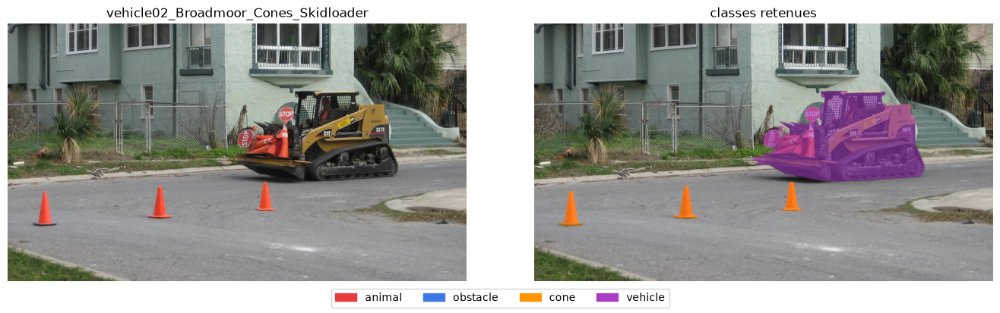

In [5]:
from PIL import Image
n = "vehicle02_Broadmoor_Cones_Skidloader"
inst = np.array(Image.open(os.path.join(C.FRAMES, n + ".labels", "labels_instance.png")))
rows = []
for i in np.unique(inst)[1:]:
    ys, xs = np.where(inst == i)
    rows.append({"instance": int(i), "pixels": len(ys), "boîte (x0, y0, x1, y1)": (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())),
                 "classe retenue": CLASSES[C.INSTANCE_CORRECTIONS[n].get(int(i), CLS_OF[n])]})
display(pd.DataFrame(rows))
LEGEND = [Patch(color=C.CLASS_COLORS[k] / 255, label=CLASSES[k]) for k in range(1, N_CLS)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(CACHE[n][0]); ax[0].set_title(n); ax[1].imshow(C.overlay(CACHE[n][0], CACHE[n][1])); ax[1].set_title("classes retenues")
for a in ax: a.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=4); plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(OUT_DIR, "cas_vehicle02.png"), dpi=90, bbox_inches="tight"); plt.show()

### 1.2 Recadrages, augmentations et tirage équilibré

- **Recadrage** : carré **centré** sur la région, côté = 1,5 × la plus grande dimension (25 % de contexte de chaque côté), complété par du gris moyen hors de l'image, puis redimensionné en 224×224.
- **Augmentations (train)** : appliquées **au cadre** sur l'image d'origine (décalage du centre de ±10 % du côté, échelle de 0,8 à 1,4), puis symétrie horizontale, luminosité et contraste. Elles imitent aussi les cadres imparfaits que produira le U-Net.
- **Tirage équilibré** : chaque classe a la même probabilité d'être tirée, chaque image pèse autant dans sa classe, chaque région autant dans son image.

Probabilité de tirer chaque classe : {'animal': 0.25, 'cone': 0.25, 'obstacle': 0.25, 'vehicle': 0.25}


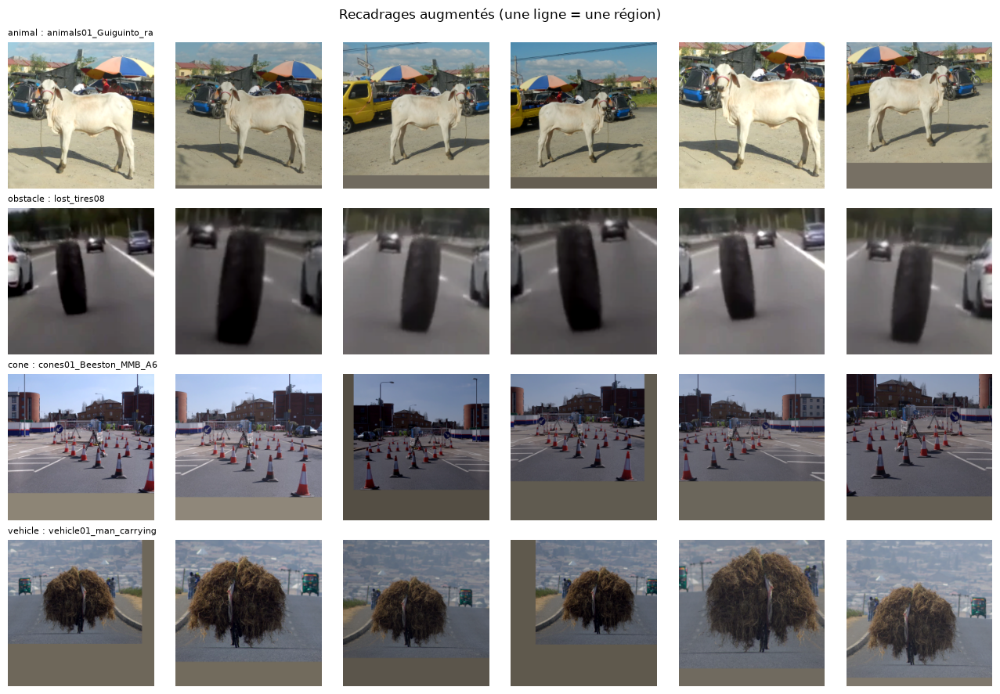

Batch : (32, 3, 224, 224) torch.float32 | étiquettes : [0, 0, 0, 0, 1, 2, 3, 3, 0, 0, 0, 2] ...


In [6]:
class CropDataset(Dataset):
    def __init__(self, regions, cache, train=False):
        self.r, self.cache, self.train = regions, cache, train
    def __len__(self):
        return len(self.r)
    def __getitem__(self, i):
        r = self.r[i]
        img = self.cache[r["name"]][0]
        if self.train:
            box = C.square_box(r["bbox"], jitter=(random.uniform(-0.1, 0.1), random.uniform(-0.1, 0.1), random.uniform(0.8, 1.4)))
            crop = C.crop_square(img, box)
            if random.random() < 0.5:
                crop = crop[:, ::-1]
            a, b = random.uniform(0.8, 1.2), random.uniform(-20, 20)
            crop = np.clip(crop.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
        else:
            crop = C.crop_square(img, C.square_box(r["bbox"]))
        return C.to_tensor(np.ascontiguousarray(crop)), r["y"]

def balanced_weights(regions):
    n_reg_img = pd.Series([r["name"] for r in regions]).value_counts().to_dict()
    img_cls = {r["name"]: r["y"] for r in regions}
    n_img_cls = pd.Series(list(img_cls.values())).value_counts().to_dict()
    return [1.0 / (n_reg_img[r["name"]] * n_img_cls[r["y"]]) for r in regions]

g = torch.Generator().manual_seed(SEED)
w = balanced_weights(REG["train"])
sampler = WeightedRandomSampler(w, num_samples=SAMPLES_PER_EPOCH, replacement=True, generator=g)
train_loader = DataLoader(CropDataset(REG["train"], CACHE, train=True), batch_size=BATCH_SIZE, sampler=sampler, num_workers=0, drop_last=True)
p = pd.Series(w, index=[OBJ_CLASSES[r["y"]] for r in REG["train"]]).groupby(level=0).sum()
print("Probabilité de tirer chaque classe :", (p / p.sum()).round(2).to_dict())

C.set_seed(SEED)
ds = CropDataset(REG["train"], CACHE, train=True)
idx = [next(i for i, r in enumerate(REG["train"]) if r["y"] == k) for k in range(4)]
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for r_, i in enumerate(idx):
    for c_ in range(6):
        x, y = ds[i]
        axes[r_, c_].imshow(C.denorm(x)); axes[r_, c_].axis("off")
    axes[r_, 0].set_title(f"{OBJ_CLASSES[y]} : {REG['train'][i]['name'][:22]}", fontsize=8, loc="left")
plt.suptitle("Recadrages augmentés (une ligne = une région)"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "augmentations.png"), dpi=80, bbox_inches="tight"); plt.show()

xb, yb = next(iter(train_loader))
print("Batch :", tuple(xb.shape), xb.dtype, "| étiquettes :", yb.tolist()[:12], "...")
assert xb.shape == (BATCH_SIZE, 3, C.CROP, C.CROP) and set(yb.tolist()) <= {0, 1, 2, 3}

## 2. Modèle

In [7]:
def build_classifier():
    return C.build_mobilenet(pretrained=PRETRAINED).to(DEVICE)

clf = build_classifier()
print(f"MobileNetV2 ({'ImageNet' if PRETRAINED else 'from scratch'}) : {C.n_params(clf) / 1e6:.2f} M paramètres")
with torch.no_grad():
    print("Entrée", (2, 3, C.CROP, C.CROP), "-> sortie", tuple(clf.eval()(torch.randn(2, 3, C.CROP, C.CROP, device=DEVICE)).shape))

MobileNetV2 (ImageNet) : 2.23 M paramètres


Entrée (2, 3, 224, 224) -> sortie (2, 4)


### 2.1 Test de sanité : apprendre par cœur 16 recadrages

Perte : 1.413 -> 0.000 | exactitude sur ces 16 recadrages : 1.00


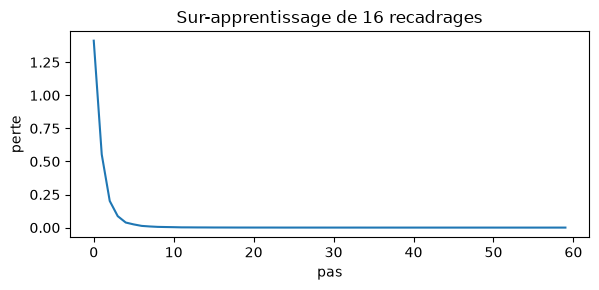

Test réussi : le modèle sait apprendre.


In [8]:
def overfit_test(steps=60):
    C.set_seed(SEED)
    sub = [REG["train"][i] for i in np.random.RandomState(0).choice(len(REG["train"]), 16, replace=False)]
    x, y = next(iter(DataLoader(CropDataset(sub, CACHE), batch_size=16)))
    x, y = x.to(DEVICE), y.to(DEVICE)
    m = build_classifier(); opt = torch.optim.Adam(m.parameters(), lr=1e-3); crit = nn.CrossEntropyLoss()
    m.train(); losses = []
    for _ in range(steps):
        opt.zero_grad(); loss = crit(m(x), y); loss.backward(); opt.step(); losses.append(loss.item())
    m.eval()
    with torch.no_grad():
        acc = (m(x).argmax(1) == y).float().mean().item()
    return losses, acc

losses, acc = overfit_test()
print(f"Perte : {losses[0]:.3f} -> {losses[-1]:.3f} | exactitude sur ces 16 recadrages : {acc:.2f}")
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.xlabel("pas"); plt.ylabel("perte"); plt.title("Sur-apprentissage de 16 recadrages")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "overfit_test.png"), dpi=100); plt.show()
assert losses[-1] < 0.5 * losses[0], "La perte ne diminue pas : bug dans la chaîne."
print("Test réussi : le modèle sait apprendre.")

## 3. Entraînement

Sélection sur le **macro-F1 de validation** calculé sur les régions réelles des 12 images de validation, chaque région pondérée par sa part de la surface d'objet de son image (chaque image pèse autant).

Epoch   1/60 | train 0.9053 | val 0.9028 | val macro-F1 0.548  <- meilleur


Epoch   2/60 | train 0.2475 | val 0.7239 | val macro-F1 0.630  <- meilleur


Epoch   3/60 | train 0.0759 | val 0.6941 | val macro-F1 0.630


Epoch   4/60 | train 0.0270 | val 0.6703 | val macro-F1 0.630


Epoch   5/60 | train 0.0167 | val 0.6561 | val macro-F1 0.630


Epoch   6/60 | train 0.0073 | val 0.6671 | val macro-F1 0.678  <- meilleur


... (14 outputs left out)

Epoch  21/60 | train 0.0009 | val 0.7425 | val macro-F1 0.680


Epoch  22/60 | train 0.0025 | val 0.7513 | val macro-F1 0.680


Epoch  23/60 | train 0.0022 | val 0.7710 | val macro-F1 0.680


Epoch  24/60 | train 0.0009 | val 0.7473 | val macro-F1 0.680
Arrêt anticipé : pas d'amélioration depuis 15 epochs.

Terminé en 8.5 min | meilleure epoch : 9 (macro-F1 val = 0.680)


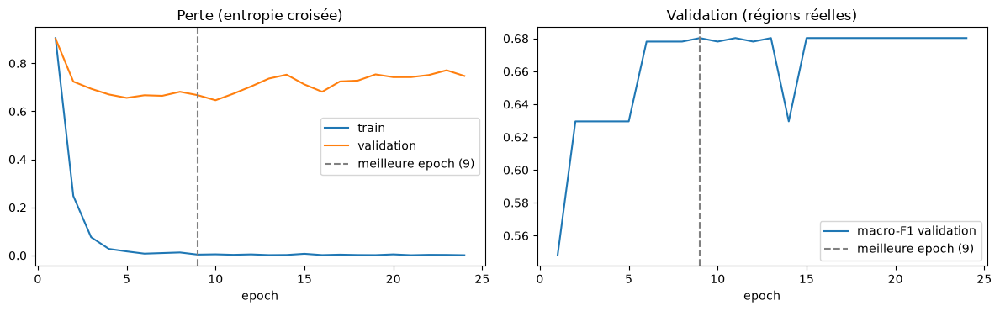

In [9]:
@torch.no_grad()
def eval_regions(model, regions):
    crops = [C.crop_square(CACHE[r["name"]][0], C.square_box(r["bbox"])) for r in regions]
    P = C.classify_crops(model, crops)
    y = np.array([r["y"] for r in regions]); sw = np.array([r["poids"] for r in regions])
    present = sorted(set(y))
    f1 = f1_score(y, P.argmax(1), labels=present, average="macro", sample_weight=sw, zero_division=0)
    loss = float(-(np.log(P[np.arange(len(y)), y] + 1e-9) * sw).sum() / sw.sum())
    return f1, loss, P

def fit(model, epochs, patience):
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW([{"params": model.features.parameters(), "lr": LR_FEATURES},
                             {"params": model.classifier.parameters(), "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    hist = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best, best_epoch, best_state, t0 = -1.0, 0, None, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True); loss = crit(model(x), y); loss.backward(); opt.step()
            run += loss.item() * x.size(0); n += x.size(0)
        sched.step()
        f1, vl, _ = eval_regions(model, REG["val"])
        hist["train_loss"].append(run / n); hist["val_loss"].append(vl); hist["val_macro_f1"].append(f1)
        better = f1 > best
        if better:
            best, best_epoch = f1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"state_dict": best_state, "epoch": epoch, "val_macro_f1": best, "pretrained": PRETRAINED,
                        "classes": OBJ_CLASSES, "crop": C.CROP}, CKPT_PATH)
        print(f"Epoch {epoch:3d}/{epochs} | train {run / n:.4f} | val {vl:.4f} | val macro-F1 {f1:.3f}" + ("  <- meilleur" if better else ""))
        if epoch - best_epoch >= patience:
            print(f"Arrêt anticipé : pas d'amélioration depuis {patience} epochs."); break
    model.load_state_dict(best_state)
    minutes = (time.time() - t0) / 60
    print(f"\nTerminé en {minutes:.1f} min | meilleure epoch : {best_epoch} (macro-F1 val = {best:.3f})")
    return hist, best_epoch, minutes

C.set_seed(SEED)
history, best_epoch, train_minutes = fit(clf, EPOCHS, PATIENCE)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="validation"); axes[0].set_title("Perte (entropie croisée)")
axes[1].plot(ep, history["val_macro_f1"], label="macro-F1 validation"); axes[1].set_title("Validation (régions réelles)")
for a in axes:
    a.axvline(best_epoch, color="gray", ls="--", label=f"meilleure epoch ({best_epoch})"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "courbes_apprentissage.png"), dpi=100, bbox_inches="tight"); plt.show()

## 4. Niveau A : le classifieur seul, avec une localisation parfaite

On classe les **régions annotées** du test. C'est le niveau d'évaluation de l'approche par boîte annotée (`bo2_classification.py`) : il dit ce que vaut la reconnaissance du type si la localisation était parfaite. La classe annoncée pour l'image est le vote des régions pondéré par leur surface.

In [10]:
def level_a(names, regions):
    _, _, P = eval_regions(clf, regions)
    rows = []
    for n in names:
        idx = [i for i, r in enumerate(regions) if r["name"] == n]
        vote = sum(regions[i]["area"] * P[i] for i in idx)
        rows.append({"name": n, "vraie": CLS_OF[n], "predite": int(np.argmax(vote)) + 1,
                     "regions": len(idx), "regions_justes": int(sum(P[i].argmax() == regions[i]["y"] for i in idx))})
    t = pd.DataFrame(rows); t["correct"] = t["vraie"] == t["predite"]
    present = sorted(t["vraie"].unique())
    yr = np.array([r["y"] for r in regions]); pr = P.argmax(1)
    res = {"accuracy_image": float(t["correct"].mean()),
           "macro_f1_image": float(f1_score(t["vraie"], t["predite"], labels=present, average="macro", zero_division=0)),
           "regions_justes": float((yr == pr).mean()),
           "macro_f1_regions": float(f1_score(yr, pr, labels=sorted(set(yr)), average="macro", zero_division=0))}
    for k in range(4):
        res[f"f1_image_{OBJ_CLASSES[k]}"] = float(f1_score(t["vraie"], t["predite"], labels=[k + 1], average="macro", zero_division=0))
    return t, res

niveau_a = {}
for s, names in [("val", val_names), ("test", test_names)]:
    tab, m = level_a(names, REG[s]); niveau_a[s] = m
    print(f"{s:5s} | images bien classées : {m['accuracy_image']:.3f} | macro-F1 image : {m['macro_f1_image']:.3f} | "
          f"régions bien classées : {m['regions_justes']:.3f} | macro-F1 régions : {m['macro_f1_regions']:.3f}")
tab_a = tab.copy(); tab_a["vraie"] = tab_a["vraie"].map(lambda k: CLASSES[k]); tab_a["predite"] = tab_a["predite"].map(lambda k: CLASSES[k])
display(tab_a)
print(classification_report(tab_a["vraie"], tab_a["predite"], labels=OBJ_CLASSES, zero_division=0, digits=3))

val   | images bien classées : 0.833 | macro-F1 image : 0.681 | régions bien classées : 0.773 | macro-F1 régions : 0.648


test  | images bien classées : 0.917 | macro-F1 image : 0.700 | régions bien classées : 0.864 | macro-F1 régions : 0.651


,name,vraie,predite,regions,regions_justes,correct
0,animals12_Collared_Peccary_crossing_the_road,animal,animal,1,1,True
1,animals13_jeune_bovin_sur_la_route,animal,animal,2,1,True
2,animals14_Dekemhare_Road,animal,animal,2,2,True
3,animals19_Porte_de_Roubaix,animal,animal,2,2,True
4,animals26_Unnamed_Road_Kazakhstan,animal,animal,1,1,True
5,animals30,animal,animal,2,2,True
6,cones04_Federation,cone,cone,1,1,True
7,cones07,cone,cone,3,3,True
8,obstacles04_cardboard_czech_hedgehog,obstacle,obstacle,2,1,True
9,obstacles09_boulder3,obstacle,obstacle,1,1,True


              precision    recall  f1-score   support

      animal      1.000     1.000     1.000         6
    obstacle      1.000     1.000     1.000         3
        cone      0.667     1.000     0.800         2
     vehicle      0.000     0.000     0.000         1

    accuracy                          0.917        12
   macro avg      0.667     0.750     0.700        12
weighted avg      0.861     0.917     0.883        12



## 5. Niveau B : chaîne complète (U-Net du BO1 → régions prédites → MobileNetV2)

C'est la situation réelle : pour une image envoyée, il n'y a ni masque annoté ni nom de fichier utile. Le U-Net du BO1 prédit le masque, on en extrait les régions, MobileNetV2 classe chacune. Le **seuil du U-Net** est choisi **sur la validation** (meilleur macro-F1 pixel de la chaîne), puis appliqué tel quel au test.

**Métriques** : F1 pixel par classe (pixel signalé **et** de la bonne classe) et macro-F1 ; part des pixels détectés qui ont la bonne classe (sépare erreur de type et erreur de localisation) ; Dice de détection ; décision par image. **Référence « classe majoritaire »** : mêmes pixels signalés, tous étiquetés animal.

U-Net du BO1 chargé (epoch 40)


Probabilités de localisation en 5 s


Seuil de localisation retenu (meilleur macro-F1 pixel sur la validation) : 0.25


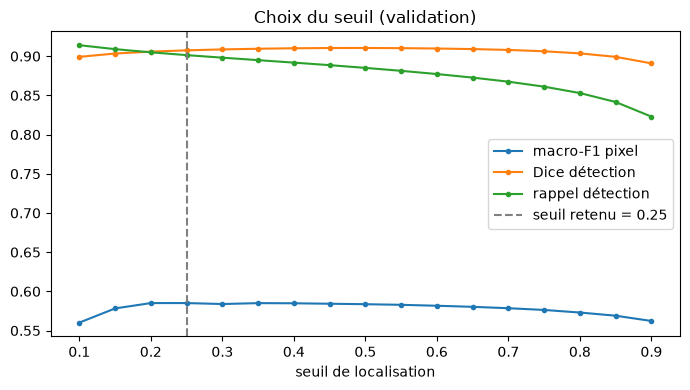

,macro_f1,f1_animal,f1_obstacle,f1_cone,f1_vehicle,bonne_classe_parmi_detectes,accuracy_image,macro_f1_image,det_dice,det_rappel
MobileNetV2 pré-entraîné : validation,0.585,0.773,0.692,0.875,0.0,0.790,0.833,0.681,0.907,0.901
MobileNetV2 pré-entraîné : TEST,0.669,0.885,0.903,0.889,0.0,1.000,0.917,0.700,0.846,0.827
Référence classe majoritaire (test),0.164,0.655,0.000,0.000,0.0,0.577,0.500,0.167,0.846,0.827


In [11]:
def evaluate(names, maps):
    s = C.scores_from_confusion(C.pixel_confusion(names, CACHE, maps))
    im, tab = C.image_level(names, CACHE, maps, CLS_OF)
    return {**s, **im}, tab

THR, res, summary, per_img_test, Cpix_test, res_maj = None, None, None, None, None, None
if HAS_LOC:
    loc, ck = C.load_loc_unet(LOC_CKPT)
    print(f"U-Net du BO1 chargé (epoch {ck.get('epoch')})")
    t0 = time.time()
    loc_probs = {"val": C.unet_probs(loc, val_names, CACHE), "test": C.unet_probs(loc, test_names, CACHE)}
    print(f"Probabilités de localisation en {time.time() - t0:.0f} s")
    thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
    sweep_val, THR = C.sweep(val_names, CACHE, lambda t: C.pipeline_maps(loc_probs["val"], clf, val_names, CACHE, t), thresholds)
    print(f"Seuil de localisation retenu (meilleur macro-F1 pixel sur la validation) : {THR:.2f}")
    plt.figure(figsize=(7, 4))
    for k, lab in [("macro_f1", "macro-F1 pixel"), ("det_dice", "Dice détection"), ("det_rappel", "rappel détection")]:
        plt.plot(sweep_val["thr"], sweep_val[k], marker="o", ms=3, label=lab)
    plt.axvline(THR, color="gray", ls="--", label=f"seuil retenu = {THR:.2f}"); plt.xlabel("seuil de localisation"); plt.title("Choix du seuil (validation)"); plt.legend()
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "choix_seuil.png"), dpi=100); plt.show()

    maps = {s: C.pipeline_maps(loc_probs[s], clf, n, CACHE, THR) for s, n in [("val", val_names), ("test", test_names)]}
    res = {s: evaluate(n, maps[s]) for s, n in [("val", val_names), ("test", test_names)]}
    maj = {n: np.where(m > 0, 1, 0).astype(np.uint8) for n, m in maps["test"].items()}
    res_maj, _ = evaluate(test_names, maj)
    cols = ["macro_f1"] + [f"f1_{c}" for c in OBJ_CLASSES] + ["bonne_classe_parmi_detectes", "accuracy_image", "macro_f1_image", "det_dice", "det_rappel"]
    label = "MobileNetV2 " + ("pré-entraîné" if PRETRAINED else "from scratch")
    summary = pd.DataFrame({label + " : validation": res["val"][0], label + " : TEST": res["test"][0],
                            "Référence classe majoritaire (test)": res_maj}).T[cols].round(3)
    display(summary)
    per_img_test = res["test"][1]
else:
    print("Niveau B sauté : poids du U-Net absents.")

### 5.1 Matrices de confusion et prédictions du test (niveau B)

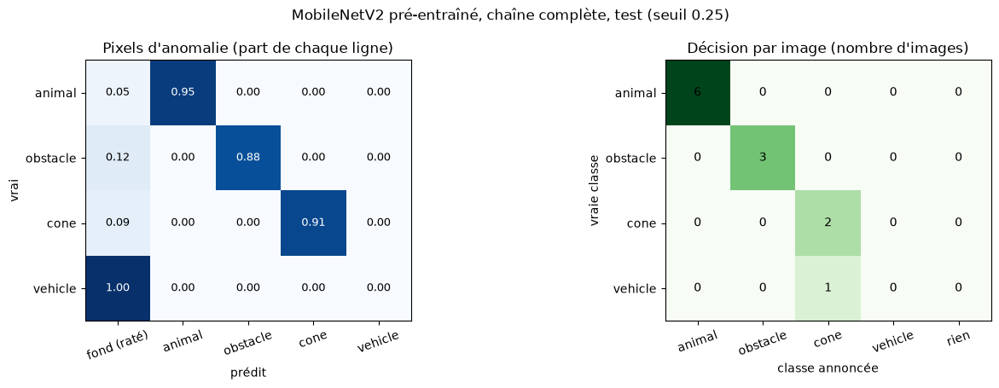

,name,vraie,predite,rappel_detection,pixels_bonne_classe,fausses_alertes_%,correct
0,animals12_Collared_Peccary_crossing_the_road,animal,animal,0.987,0.987,0.518,True
1,animals13_jeune_bovin_sur_la_route,animal,animal,0.932,0.932,0.319,True
2,animals14_Dekemhare_Road,animal,animal,0.985,0.985,1.970,True
3,animals19_Porte_de_Roubaix,animal,animal,0.861,0.861,1.239,True
4,animals26_Unnamed_Road_Kazakhstan,animal,animal,0.974,0.974,3.461,True
5,animals30,animal,animal,0.947,0.944,1.559,True
6,cones04_Federation,cone,cone,0.963,0.963,0.066,True
7,cones07,cone,cone,0.816,0.816,0.116,True
8,obstacles04_cardboard_czech_hedgehog,obstacle,obstacle,0.611,0.611,0.659,True
9,obstacles09_boulder3,obstacle,obstacle,0.963,0.963,0.696,True


              precision    recall  f1-score   support

      animal      1.000     1.000     1.000         6
    obstacle      1.000     1.000     1.000         3
        cone      0.667     1.000     0.800         2
     vehicle      0.000     0.000     0.000         1

    accuracy                          0.917        12
   macro avg      0.667     0.750     0.700        12
weighted avg      0.861     0.917     0.883        12



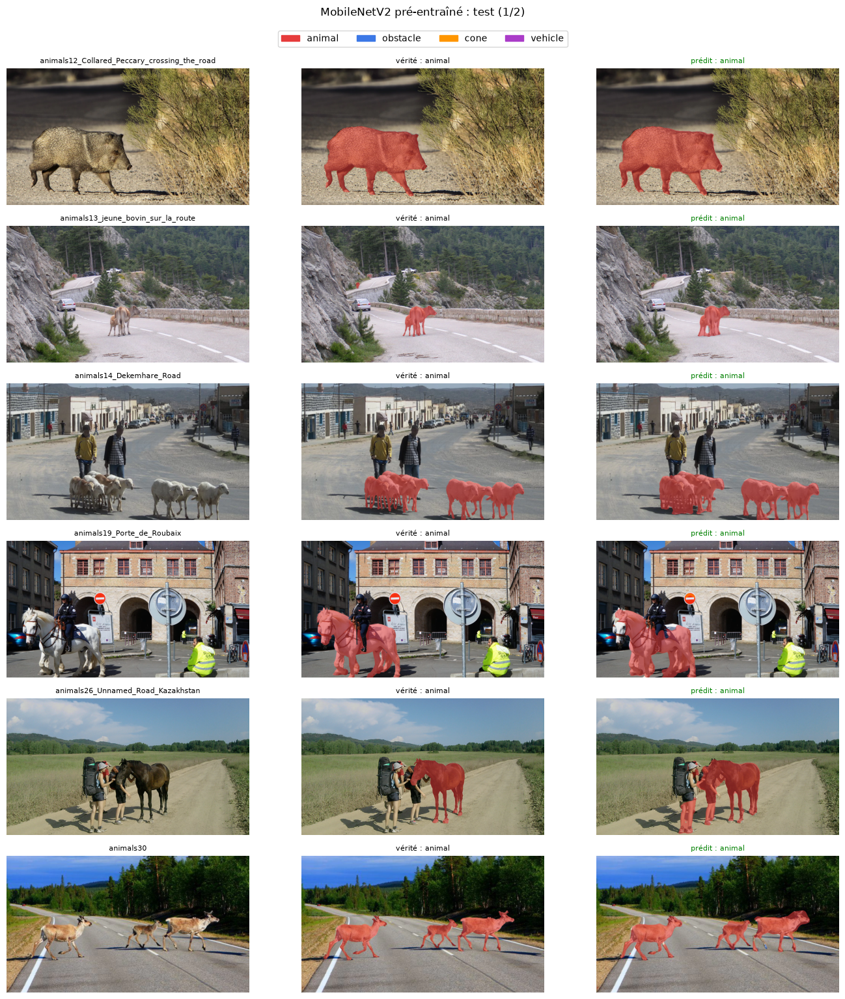

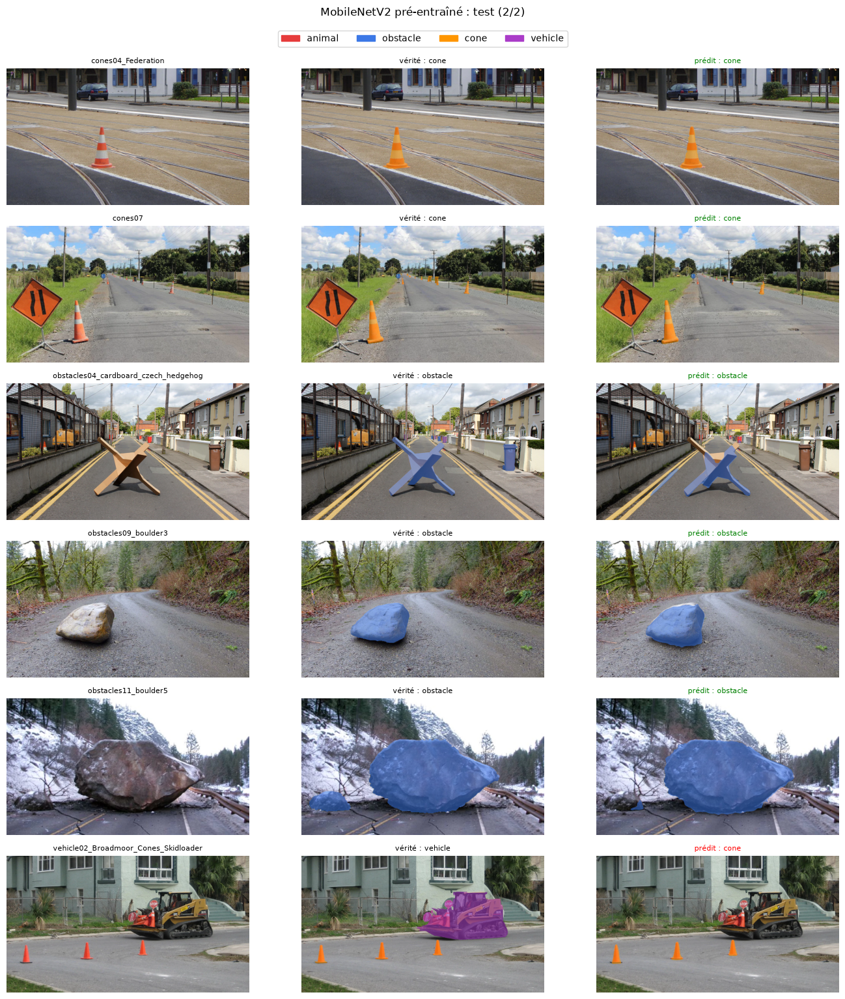

In [12]:
def plot_confusions(Cpix, Cimg, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    M = Cpix[1:, :] / np.maximum(Cpix[1:, :].sum(1, keepdims=True), 1)
    axes[0].imshow(M, cmap="Blues", vmin=0, vmax=1)
    axes[0].set_xticks(range(N_CLS)); axes[0].set_xticklabels(["fond (raté)"] + OBJ_CLASSES, rotation=20)
    axes[0].set_yticks(range(4)); axes[0].set_yticklabels(OBJ_CLASSES); axes[0].set_xlabel("prédit"); axes[0].set_ylabel("vrai")
    for i in range(4):
        for j in range(N_CLS):
            axes[0].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] > 0.5 else "black", fontsize=9)
    axes[0].set_title("Pixels d'anomalie (part de chaque ligne)")
    axes[1].imshow(Cimg, cmap="Greens")
    axes[1].set_xticks(range(5)); axes[1].set_xticklabels(OBJ_CLASSES + ["rien"], rotation=20)
    axes[1].set_yticks(range(4)); axes[1].set_yticklabels(OBJ_CLASSES); axes[1].set_xlabel("classe annoncée"); axes[1].set_ylabel("vraie classe")
    for i in range(4):
        for j in range(5):
            axes[1].text(j, i, int(Cimg[i, j]), ha="center", va="center", fontsize=10)
    axes[1].set_title("Décision par image (nombre d'images)")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=100, bbox_inches="tight"); plt.show()

def plot_preds(names, maps_, fname, title):
    fig, axes = plt.subplots(len(names), 3, figsize=(14, 2.5 * len(names)), squeeze=False)
    for r, n in enumerate(names):
        img, gt = CACHE[n]
        pred_cls = C.image_decision(maps_[n])
        axes[r, 0].imshow(img); axes[r, 0].set_title(n[:45], fontsize=8)
        axes[r, 1].imshow(C.overlay(img, gt)); axes[r, 1].set_title(f"vérité : {CLASSES[CLS_OF[n]]}", fontsize=8)
        axes[r, 2].imshow(C.overlay(img, maps_[n])); axes[r, 2].set_title(f"prédit : {CLASSES[pred_cls] if pred_cls else 'rien'}", fontsize=8,
                                                                      color="green" if pred_cls == CLS_OF[n] else "red")
        for a in axes[r]: a.axis("off")
    fig.legend(handles=LEGEND, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0)); fig.suptitle(title, y=1.02)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=80, bbox_inches="tight"); plt.show()

if HAS_LOC:
    Cpix_test = C.pixel_confusion(test_names, CACHE, maps["test"])
    plot_confusions(Cpix_test, C.image_confusion(per_img_test), f"{label}, chaîne complète, test (seuil {THR:.2f})", "confusion_test.png")
    t = per_img_test.copy()
    t["vraie"] = t["vraie"].map(lambda k: CLASSES[k]); t["predite"] = t["predite"].map(lambda k: CLASSES[k] if k else "rien")
    display(t.round(3))
    print(classification_report(t["vraie"], t["predite"], labels=OBJ_CLASSES, zero_division=0, digits=3))
    plot_preds(test_names[:6], maps["test"], "predictions_test_1.png", label + " : test (1/2)")
    plot_preds(test_names[6:], maps["test"], "predictions_test_2.png", label + " : test (2/2)")

## 6. Taille et temps d'inférence (CPU)

In [13]:
crop0 = C.crop_square(CACHE[test_names[0]][0], C.square_box(REG["test"][0]["bbox"]))
ms_crop = C.time_inference(lambda: C.classify_crops(clf, [crop0]))
taille = {"params_M": round(C.n_params(clf) / 1e6, 3), "fichier_Mo": round(os.path.getsize(CKPT_PATH) / 1e6, 1), "ms_par_recadrage": round(ms_crop, 1)}
print(f"Paramètres : {taille['params_M']} M | fichier .pt : {taille['fichier_Mo']} Mo | classification d'un recadrage : {ms_crop:.1f} ms (médiane, CPU)")

Paramètres : 2.229 M | fichier .pt : 9.2 Mo | classification d'un recadrage : 15.4 ms (médiane, CPU)


## 7. Sauvegarde des résultats

In [14]:
tab_a.to_csv(os.path.join(OUT_DIR, "niveau_A_par_image_test.csv"), index=False)
if HAS_LOC:
    summary.to_csv(os.path.join(OUT_DIR, "tableau_recapitulatif.csv"))
    t.to_csv(os.path.join(OUT_DIR, "resultats_par_image_test.csv"), index=False)
results = {
    "config": {"run_name": RUN_NAME, "modele": "MobileNetV2 torchvision", "pretrained_imagenet": PRETRAINED, "crop": C.CROP,
               "margin": C.MARGIN, "merge_px": C.MERGE_PX, "min_px": C.MIN_PX, "batch_size": BATCH_SIZE,
               "samples_per_epoch": SAMPLES_PER_EPOCH, "epochs_max": EPOCHS, "epochs_run": len(history["train_loss"]),
               "best_epoch": best_epoch, "train_minutes": round(train_minutes, 1), "seed": SEED, "lr_features": LR_FEATURES,
               "lr_head": LR_HEAD, "quick_test": QUICK_TEST, "classes": OBJ_CLASSES},
    "taille": taille,
    "val_macro_f1_selection": max(history["val_macro_f1"]),
    "niveau_A": niveau_a,
    "niveau_B": None if not HAS_LOC else {"threshold": THR, "test": res["test"][0], "val": res["val"][0],
                                          "baseline_classe_majoritaire_test": res_maj, "confusion_pixels_test": Cpix_test.tolist()},
}
with open(os.path.join(OUT_DIR, "resultats_bo2.json"), "w", encoding="utf-8") as f:
    json.dump(results, f, indent=1, ensure_ascii=False)
print("Résultats enregistrés dans", os.path.basename(OUT_DIR))

Résultats enregistrés dans outputs_bo2_mobilenetv2_pretrained
